In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
import ast 

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

def clean_list(skills):
    if pd.notna(skills):
        return ast.literal_eval(skills)
    
df['job_skills'] = df['job_skills'].apply(clean_list)

In [ ]:
df_exploded = df.explode('job_skills')

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,r,"{'analyst_tools': ['power bi', 'tableau'], 'pr..."
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,python,"{'analyst_tools': ['power bi', 'tableau'], 'pr..."
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,sql,"{'analyst_tools': ['power bi', 'tableau'], 'pr..."
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,nosql,"{'analyst_tools': ['power bi', 'tableau'], 'pr..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785739,Data Engineer,"Principal Associate, Data Engineer (Remote-Eli...","Newark, New Jersey, Amerika Serikat",melalui Recruit.net,Pekerjaan tetap,False,Sudan,2023-03-12 06:32:15,False,False,Sudan,NaN,NaN,NaN,Capital One,kafka,"{'cloud': ['aws', 'snowflake', 'azure', 'redsh..."
785739,Data Engineer,"Principal Associate, Data Engineer (Remote-Eli...","Newark, New Jersey, Amerika Serikat",melalui Recruit.net,Pekerjaan tetap,False,Sudan,2023-03-12 06:32:15,False,False,Sudan,NaN,NaN,NaN,Capital One,kubernetes,"{'cloud': ['aws', 'snowflake', 'azure', 'redsh..."
785739,Data Engineer,"Principal Associate, Data Engineer (Remote-Eli...","Newark, New Jersey, Amerika Serikat",melalui Recruit.net,Pekerjaan tetap,False,Sudan,2023-03-12 06:32:15,False,False,Sudan,NaN,NaN,NaN,Capital One,docker,"{'cloud': ['aws', 'snowflake', 'azure', 'redsh..."
785740,Software Engineer,AWS System Analyst,India,melalui Trigyn,Pekerjaan tetap,False,India,2023-03-13 06:16:31,False,False,India,NaN,NaN,NaN,Trigyn,aws,"{'cloud': ['aws'], 'other': ['flow']}"


In [3]:
df_exploded['job_skills'].value_counts()

job_skills
sql             384849
python          380909
aws             145381
azure           132527
r               130892
                 ...  
rubyon rails         1
visualbasic          1
gtx                  1
wimi                 1
rocketchat           1
Name: count, Length: 252, dtype: int64

In [4]:
exploded_pivot =df_exploded.pivot_table(
    index='job_title_short', 
    columns='job_skills',
    aggfunc='size',
    )

In [5]:
top_3_jobs = df['job_title_short'].value_counts().nlargest(3).index

In [6]:
exploded_pivot.loc[top_3_jobs]

job_skills,airflow,airtable,alteryx,angular,angular.js,ansible,apl,arch,asana,asp.net,...,wimi,windows,wire,word,workfront,wrike,wsl,xamarin,yarn,zoom
job_title_short,,,,,,,,,,,,,,,,,,,,,
Data Analyst,2002.0,88.0,4570.0,376.0,2.0,186.0,53.0,63.0,176.0,181.0,...,NaN,2022.0,101.0,13562.0,31.0,39.0,16.0,2.0,76.0,465.0
Data Engineer,25505.0,68.0,2294.0,1446.0,45.0,3380.0,17.0,47.0,82.0,255.0,...,NaN,3329.0,90.0,3335.0,4.0,6.0,16.0,10.0,1263.0,329.0
Data Scientist,3915.0,65.0,2068.0,736.0,12.0,448.0,101.0,75.0,98.0,140.0,...,1.0,1874.0,57.0,5206.0,2.0,8.0,31.0,5.0,249.0,361.0


In [16]:
top_15_skills = df_exploded['job_skills'].value_counts().nlargest(15).index
top_15_skills

Index(['sql', 'python', 'aws', 'azure', 'r', 'tableau', 'excel', 'spark',
       'power bi', 'java', 'sas', 'hadoop', 'scala', 'snowflake',
       'databricks'],
      dtype='str', name='job_skills')

<Axes: xlabel='job_title_short'>

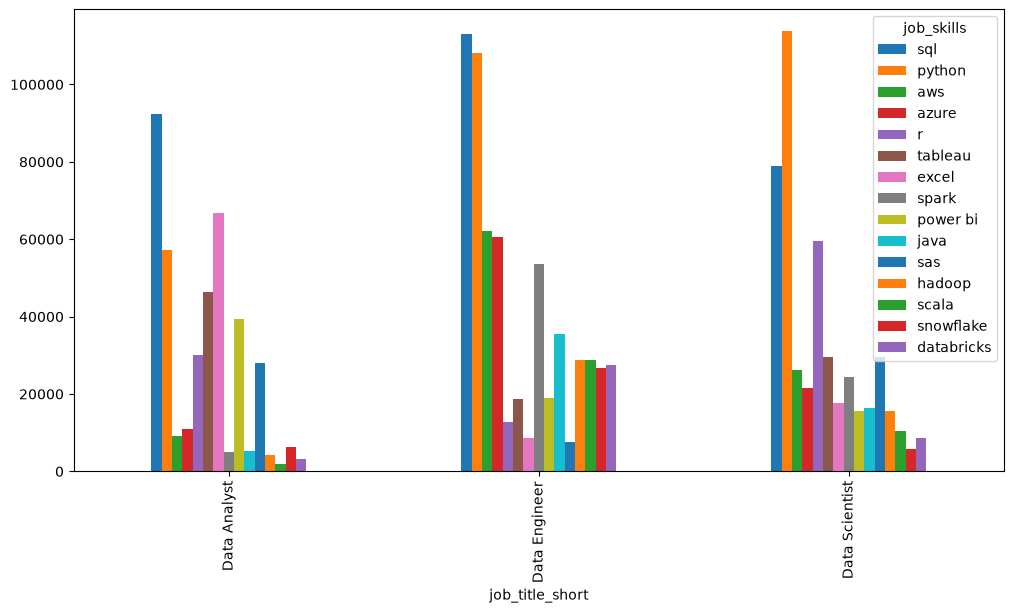

In [8]:
exploded_pivot.loc[top_3_jobs , top_15_skills].plot(kind='bar', figsize=(12, 6))

In [9]:
top_1_jobs = df['job_title_short'].value_counts().nlargest(1).index

In [10]:
exploded_pivot.loc[top_1_jobs , top_15_skills]

job_skills,sql,python,aws,azure,r,tableau,excel,spark,power bi,java,sas,hadoop,scala,snowflake,databricks
job_title_short,,,,,,,,,,,,,,,
Data Analyst,92428.0,57190.0,9047.0,10913.0,29996.0,46455.0,66860.0,5029.0,39380.0,5238.0,27998.0,4184.0,1857.0,6178.0,3152.0


<Axes: xlabel='job_title_short'>

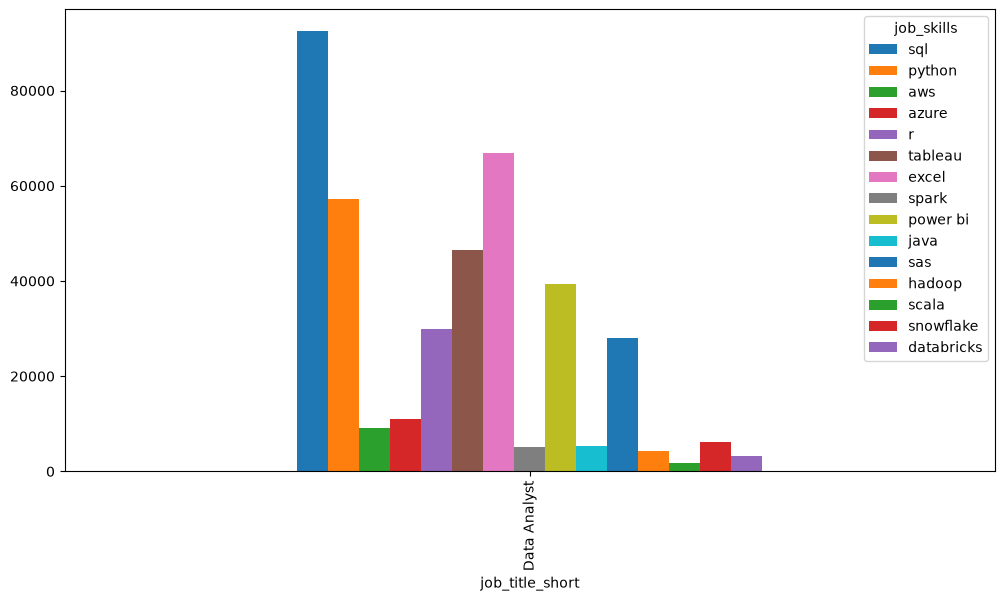

In [11]:
exploded_pivot.loc[top_1_jobs , top_15_skills].plot(kind='bar', figsize=(12, 6))

In [12]:
exploded_pivot_1 = df_exploded.pivot_table(
    index='job_skills', 
    columns='job_title_short',
    aggfunc='size',
    )

In [13]:
exploded_pivot_1.loc[top_15_skills , top_1_jobs]

job_title_short,Data Analyst
job_skills,
sql,92428.0
python,57190.0
aws,9047.0
azure,10913.0
r,29996.0
tableau,46455.0
excel,66860.0
spark,5029.0
power bi,39380.0


Text(0, 0.5, 'Count')

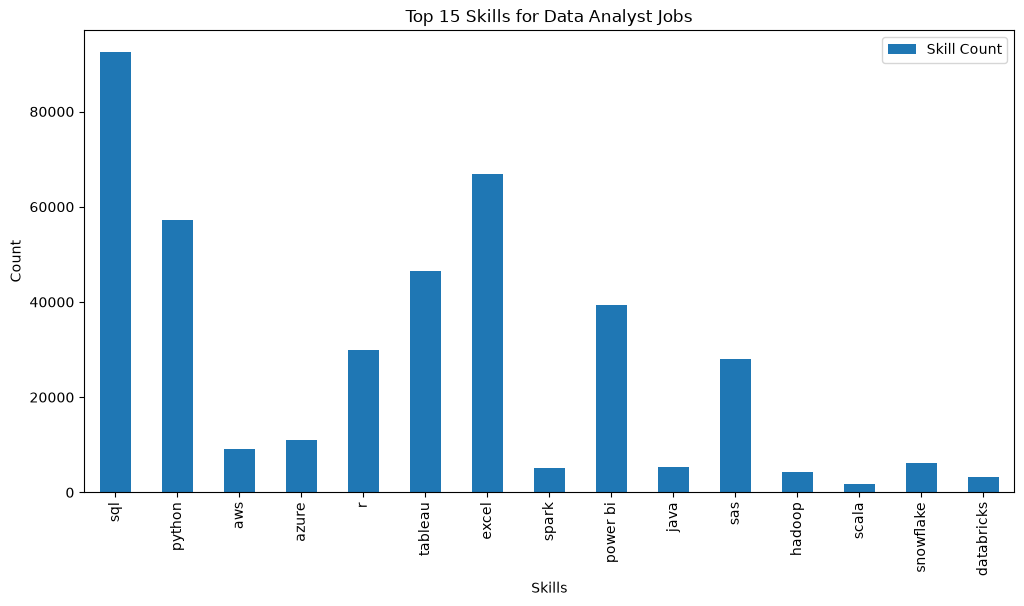

In [14]:
exploded_pivot_1.loc[top_15_skills , top_1_jobs].plot(kind='bar', figsize=(12, 6), legend=False)
plt.title(f'Top {len(top_15_skills)} Skills for {top_1_jobs[0]} Jobs')
plt.legend(labels=['Skill Count'])
plt.xlabel('Skills')
plt.ylabel('Count')